# Clase 43 · Agrupamiento por densidad y evaluación · sobre CAMMESA
**Aprendizaje Automático y Grandes Datos · UNRaf · 2026 · Grupo 6**

Pregunta: la clase 41 partió a los agentes del mercado eléctrico en tres grupos con k-medias. Hoy, otra idea de grupo: **regiones densas** de agentes parecidos, de cualquier forma, sin decir cuántas hay, y con lo que queda afuera como **ruido**. Y la pregunta de la unidad: sin etiquetas, ¿cómo se sabe si un agrupamiento es bueno?

Tres partes: **1 · los datos** (los mismos perfiles de la clase 41, escalados; y una figura construida para ver qué hace DBSCAN), **2 · el modelo** (DBSCAN: eps, centrales y ruido; quiénes quedan afuera; los índices para evaluar), **3 · usarlo** (¿un agente nuevo se parece a alguno?, y la app Streamlit).

## 1 · Los datos

Las 868 series (agente + tarifa) con 24 meses o más, cada una resumida en los seis números de la clase 41: tamaño, estacionalidad, volatilidad, tendencia anual, frecuencia de caídas fuertes y variabilidad. Escaladas: **eps es una distancia**, y sin escalar sería casi una distancia en tamaño.

In [2]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
from sklearn.preprocessing import StandardScaler

CANDIDATAS = [Path("datos/demanda-ltimos-aos.csv"), Path("demanda-ltimos-aos.csv"), Path("../datos/demanda-ltimos-aos.csv"), Path("../Regresion/datos/demanda-ltimos-aos.csv")]
RUTA = next((p for p in CANDIDATAS if p.exists()), None)
if RUTA is None:
    raise FileNotFoundError(f"No encontré el CSV. Ponelo en alguna de estas rutas: {[str(p) for p in CANDIDATAS]}")
demanda = pd.read_csv(RUTA, encoding="utf-8-sig", dtype={"indice_tiempo": str})
demanda["periodo"] = pd.PeriodIndex(demanda["indice_tiempo"], freq="M")
demanda["serie"] = demanda["agente_nemo"] + " | " + demanda["tarifa"]
demanda = demanda.sort_values(["serie", "periodo"])

def perfil(g):
    """Los seis números de la clase 41: cómo se comporta la demanda de una serie a lo largo de su historia."""
    s = g.set_index("periodo")["demanda_MWh"]
    if len(s) < 24 or (s <= 0).mean() > 0.1:
        return None
    pos = s[s > 0]
    cambio = (s / s.shift(1) - 1)[s.shift(1) > 0].clip(-1, 3)
    mes = pos.index.month
    verano, invierno = pos[np.isin(mes, [12, 1, 2])].mean(), pos[np.isin(mes, [6, 7, 8])].mean()
    anios = np.array([(p - pos.index[0]).n for p in pos.index]) / 12
    return pd.Series({"log_tamano": np.log10(pos.mean()), "estacionalidad": np.log2(verano / invierno),
                      "volatilidad": cambio.abs().median(), "tendencia_anual": np.polyfit(anios, np.log10(pos.to_numpy()), 1)[0],
                      "frac_caidas": (cambio < -0.15).mean(), "cv": pos.std() / pos.mean()})
with warnings.catch_warnings():
    warnings.simplefilter("ignore")
    perfiles = demanda.groupby("serie").apply(perfil).dropna()
COLUMNAS = ["log_tamano", "estacionalidad", "volatilidad", "tendencia_anual", "frac_caidas", "cv"]
preparar = StandardScaler().fit(perfiles[COLUMNAS])
Z = preparar.transform(perfiles[COLUMNAS])
print(f"{len(perfiles)} series · Z: {Z.shape[0]} × {Z.shape[1]}, media 0 y desvío 1 por columna")

868 series · Z: 868 × 6, media 0 y desvío 1 por columna


### Qué hace la densidad, con una figura construida

Dos medias lunas (datos **construidos**, el ejemplo del material), igual que en la cátedra. k-medias las parte por la mitad: un grupo es «lo que está cerca de un punto». DBSCAN las encuentra enteras: un grupo es «una cadena de puntos con vecinos cerca», de cualquier forma. Y los puntos sueltos quedan como ruido (etiqueta −1, en gris).

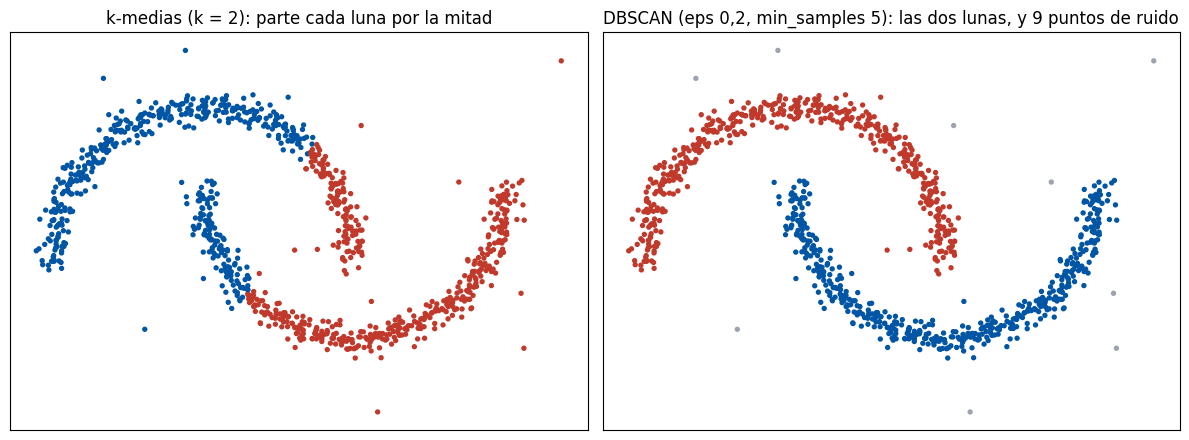

DBSCAN: un punto es «central» si tiene al menos min_samples vecinos a menos de eps; las cadenas de centrales son los grupos; lo que no llega a ninguna central es ruido.


In [3]:
from sklearn.datasets import make_moons
from sklearn.cluster import KMeans, DBSCAN

X_lunas, _ = make_moons(n_samples=1000, noise=0.05, random_state=42)
X_lunas = np.vstack([X_lunas, np.random.default_rng(2026).uniform([-1.5, -1.0], [2.5, 1.5], size=(20, 2))])     # más 20 puntos sueltos
color = lambda etiquetas: ["#9ca3af" if e == -1 else ["#0055a5", "#c0392b", "#2e8b57"][e % 3] for e in etiquetas]
fig, (a, b) = plt.subplots(1, 2, figsize=(12, 4.5))
a.scatter(X_lunas[:, 0], X_lunas[:, 1], c=color(KMeans(n_clusters=2, n_init=10, random_state=2026).fit_predict(X_lunas)), s=8); a.set_title("k-medias (k = 2): parte cada luna por la mitad"); a.set_xticks([]); a.set_yticks([])
db = DBSCAN(eps=0.2, min_samples=5).fit(X_lunas)
b.scatter(X_lunas[:, 0], X_lunas[:, 1], c=color(db.labels_), s=8); b.set_title(f"DBSCAN (eps 0,2, min_samples 5): las dos lunas, y {(db.labels_ == -1).sum()} puntos de ruido"); b.set_xticks([]); b.set_yticks([])
plt.tight_layout(); plt.show()
print("DBSCAN: un punto es «central» si tiene al menos min_samples vecinos a menos de eps; las cadenas de centrales son los grupos; lo que no llega a ninguna central es ruido.")

## 2 · El modelo

### Elegir eps: la distancia al 5.º vecino

eps no se deja por defecto. Para cada serie, la distancia a su 5.º vecino más cercano; ordenadas de menor a mayor, la curva es plana para la mayoría (tienen vecinos cerca) y sube de golpe para unas pocas (no tienen). Un eps en el codo deja a la mayoría adentro y a las pocas como ruido. Acá el codo está cerca del percentil 90.

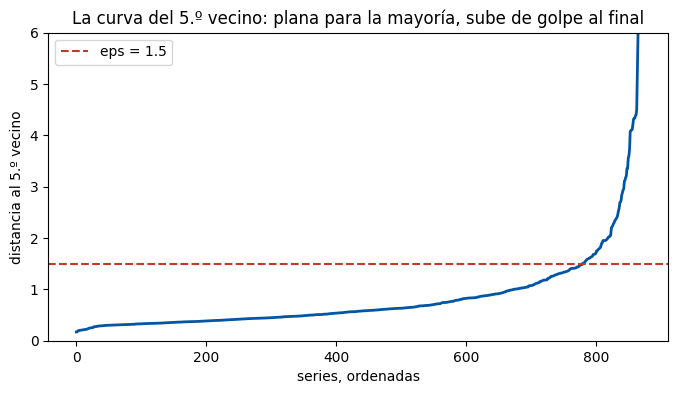

Mediana 0.57 · percentil 90 1.51 · máximo 8.07 · series con el 5.º vecino a más de 1.5: 89 de 868


In [4]:
from sklearn.neighbors import NearestNeighbors

d5, _ = NearestNeighbors(n_neighbors=5).fit(Z).kneighbors(Z); d5 = d5[:, -1]            # distancia de cada serie a su 5.º vecino (contándose)
EPS = 1.5
fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(np.sort(d5), color="#0055a5", lw=2); ax.axhline(EPS, color="#c0392b", ls="--", label=f"eps = {EPS}")
ax.set_ylim(0, 6); ax.set_xlabel("series, ordenadas"); ax.set_ylabel("distancia al 5.º vecino"); ax.legend(); ax.set_title("La curva del 5.º vecino: plana para la mayoría, sube de golpe al final")
plt.show()
print(f"Mediana {np.median(d5):.2f} · percentil 90 {np.percentile(d5, 90):.2f} · máximo {d5.max():.2f} · series con el 5.º vecino a más de {EPS}: {(d5 > EPS).sum()} de {len(Z)}")

### DBSCAN sobre los agentes

Con eps 1,5 y min_samples 5. Lo que sale, igual que con los socios del gimnasio: **un solo grupo** y ruido. En seis columnas los agentes no forman islas separadas por vacío: hay un centro denso y bordes ralos. Con otros eps pasa lo mismo: más chico, mucho ruido y algún grupito de cuatro o cinco series; más grande, un grupo y menos ruido.

In [5]:
from sklearn.cluster import KMeans, DBSCAN

filas = []
for eps in [0.5, 0.7, 1.0, 1.2, 1.5, 2.0]:
    et = DBSCAN(eps=eps, min_samples=5).fit_predict(Z)
    filas.append({"eps": eps, "grupos": et.max() + 1, "ruido": int((et == -1).sum()), "% ruido": round(100 * (et == -1).mean(), 1),
                  "tamaños de los grupos": np.bincount(et[et >= 0]).tolist()})
display(pd.DataFrame(filas))
dbscan = DBSCAN(eps=EPS, min_samples=5).fit(Z)
ruido = dbscan.labels_ == -1
centrales = dbscan.components_                                                          # las coordenadas (escaladas) de las centrales
print(f"eps {EPS}: {dbscan.labels_.max() + 1} grupo · {len(centrales)} centrales · {ruido.sum()} series de ruido ({100 * ruido.mean():.1f} %)")

,eps,grupos,ruido,% ruido,tamaños de los grupos
0,0.5,3,427,49.2,"[432, 4, 5]"
1,0.7,1,261,30.1,[607]
2,1.0,2,156,18.0,"[707, 5]"
3,1.2,3,105,12.1,"[749, 8, 6]"
4,1.5,1,56,6.5,[812]
5,2.0,1,40,4.6,[828]


eps 1.5: 1 grupo · 779 centrales · 56 series de ruido (6.5 %)


### Quiénes quedan como ruido

Las series sin cinco vecinos a menos de eps. Cajas de cuatro columnas, ruido contra grupo, y un diagrama de dispersión con el ruido en gris. Y la comparación con los tres grupos de k-medias de la clase 41: ¿de qué grupo sale el ruido?

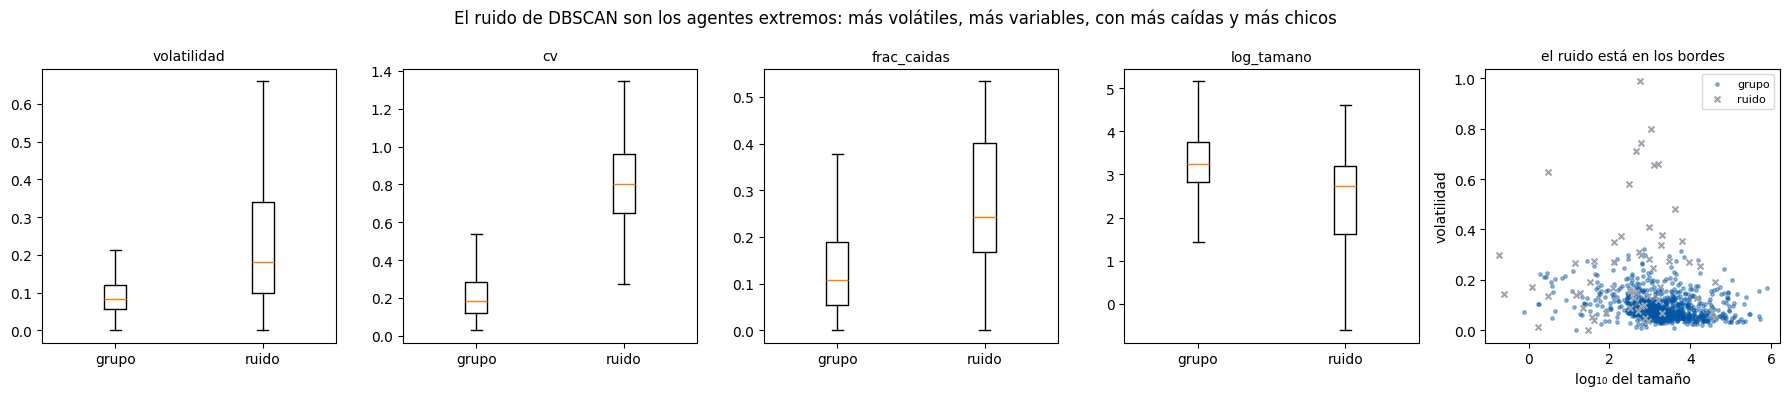

Mediana en el ruido contra el grupo: {'volatilidad': (0.181, 0.084), 'cv': (0.804, 0.183), 'frac_caidas': (0.243, 0.108), 'log_tamano': (2.736, 3.249)}


DBSCAN,región densa,ruido
grupo de k-medias (clase 41),,
"chicos, algo más de invierno y en crecimiento",262,22
grandes y estables,536,3
"muy variables, de verano y en baja",14,31


Los diez agentes más extremos del ruido (por variabilidad):


,log_tamano,estacionalidad,volatilidad,tendencia_anual,frac_caidas,cv
serie,,,,,,
CRANCH3W | TARIFA USUARIO NO RESIDENCIAL >=300KWH,1.63,0.48,0.04,-0.37,0.14,1.89
SHELDSCA | GUMAS/AUTOGENERADORES,2.75,-0.77,0.99,-0.35,0.44,1.87
CMONTE1W | TARIFA USUARIO NO RESIDENCIAL >=300KWH,1.36,0.98,0.09,0.01,0.10,1.64
YPFTREUZ | GUMAS/AUTOGENERADORES,3.02,0.67,0.80,1.17,0.32,1.50
YPF-SPRZ | GUMAS/AUTOGENERADORES,3.11,-0.06,0.66,0.77,0.41,1.46
EMACHIJZ | GUMAS/AUTOGENERADORES,3.47,-0.22,0.27,-0.88,0.52,1.34
AGRIPTCY | GUMAS/AUTOGENERADORES,1.91,0.84,0.07,-0.44,0.12,1.31
BOPPCA1Y | GUMAS/AUTOGENERADORES,2.66,0.03,0.15,-1.03,0.39,1.23
YPFPTRZZ | GUMAS/AUTOGENERADORES,2.48,0.21,0.58,0.27,0.41,1.18


In [6]:
fig, ejes = plt.subplots(1, 5, figsize=(18, 4))
for ax, col in zip(ejes[:4], ["volatilidad", "cv", "frac_caidas", "log_tamano"]):
    ax.boxplot([perfiles.loc[~ruido, col], perfiles.loc[ruido, col]], tick_labels=["grupo", "ruido"], showfliers=False); ax.set_title(col, fontsize=10)
ax = ejes[4]
ax.scatter(perfiles.loc[~ruido, "log_tamano"], perfiles.loc[~ruido, "volatilidad"], s=6, alpha=0.4, color="#0055a5", label="grupo")
ax.scatter(perfiles.loc[ruido, "log_tamano"], perfiles.loc[ruido, "volatilidad"], s=18, color="#9ca3af", marker="x", label="ruido")
ax.set_xlabel("log₁₀ del tamaño"); ax.set_ylabel("volatilidad"); ax.legend(fontsize=8); ax.set_title("el ruido está en los bordes", fontsize=10)
fig.suptitle("El ruido de DBSCAN son los agentes extremos: más volátiles, más variables, con más caídas y más chicos")
plt.tight_layout(); plt.show()
print("Mediana en el ruido contra el grupo:", {c: (round(float(perfiles.loc[ruido, c].median()), 3), round(float(perfiles.loc[~ruido, c].median()), 3)) for c in ["volatilidad", "cv", "frac_caidas", "log_tamano"]})

kmedias = KMeans(n_clusters=3, n_init=10, random_state=2026).fit(Z)                       # el de la clase 41: misma Z, misma semilla
centros = pd.DataFrame(preparar.inverse_transform(kmedias.cluster_centers_), columns=COLUMNAS)
j_grande = int(np.argmax(centros["log_tamano"].to_numpy())); resto = [j for j in range(3) if j != j_grande]
j_verano = max(resto, key=lambda j: centros["estacionalidad"].iloc[j]); j_otro = [j for j in resto if j != j_verano][0]
nombres = {j_grande: "grandes y estables", j_verano: "muy variables, de verano y en baja", j_otro: "chicos, algo más de invierno y en crecimiento"}
cruce = pd.crosstab(pd.Series([nombres[g] for g in kmedias.labels_], name="grupo de k-medias (clase 41)"), pd.Series(np.where(ruido, "ruido", "región densa"), name="DBSCAN"))
display(cruce)
print("Los diez agentes más extremos del ruido (por variabilidad):")
display(perfiles[ruido].sort_values("cv", ascending=False).head(10)[COLUMNAS].round(2))

Dos lecturas. El ruido son los agentes que no se parecen a nadie: la lista de lo que la clase 46 llama anomalías, acá saliendo de agrupar. Y una que no estaba en la cátedra: **la mayor parte del grupo chico de k-medias («muy variables, de verano y en baja») es ruido para DBSCAN**. k-medias tiene que mandar a cada agente a algún centroide, y a los extremos les armó un grupo propio; la densidad dice que esos agentes no forman un grupo, sino que están sueltos.

### Evaluar sin etiquetas

Tres índices internos (solo con los datos y las etiquetas): **silueta** (de −1 a 1, mayor es mejor), **Davies-Bouldin** (dispersión sobre distancia entre centroides, menor es mejor) y **Calinski-Harabasz** (mayor es mejor). Sobre k-medias con k de 2 a 6. Para DBSCAN con un solo grupo no se pueden calcular (necesitan dos), y con el ruido como «grupo» dan números sin sentido.

,silueta (mayor),Davies-Bouldin (menor),Calinski-Harabasz (mayor)
k,,,
2,0.384,1.515,287.808
3,0.301,1.576,230.512
4,0.297,1.386,218.919
5,0.288,1.337,205.353
6,0.277,1.237,208.528


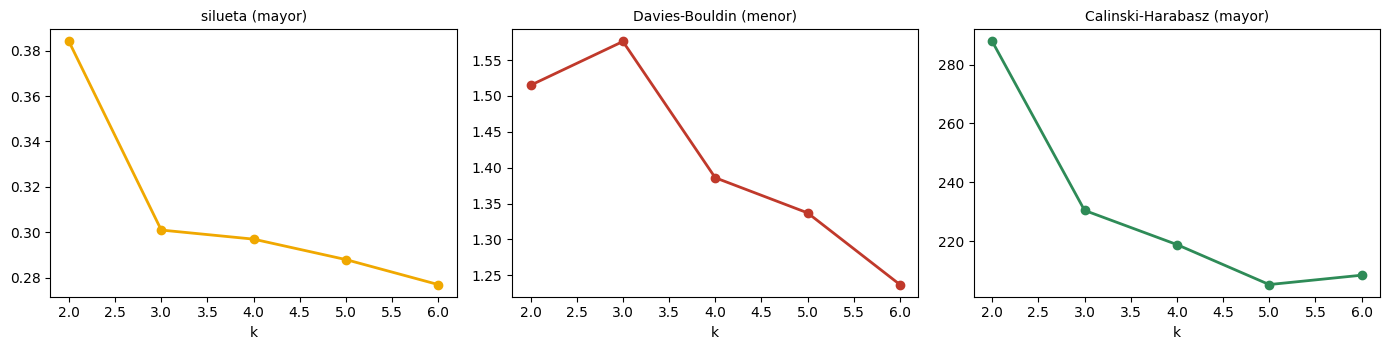

La silueta y Calinski-Harabasz prefieren k = 2; Davies-Bouldin empeora de 2 a 3 y después mejora hasta 6: no coinciden entre sí, porque miden compacidad y separación con fórmulas distintas, no verdad.


In [7]:
from sklearn.metrics import silhouette_score, davies_bouldin_score, calinski_harabasz_score

filas = []
for k in range(2, 7):
    et = KMeans(n_clusters=k, n_init=10, random_state=2026).fit_predict(Z)
    filas.append({"k": k, "silueta (mayor)": silhouette_score(Z, et), "Davies-Bouldin (menor)": davies_bouldin_score(Z, et), "Calinski-Harabasz (mayor)": calinski_harabasz_score(Z, et)})
indices = pd.DataFrame(filas).set_index("k").round(3); display(indices)
fig, ejes = plt.subplots(1, 3, figsize=(14, 3.6))
for ax, col, c_ in zip(ejes, indices.columns, ["#f0a800", "#c0392b", "#2e8b57"]):
    ax.plot(indices.index, indices[col], marker="o", color=c_, lw=2); ax.set_xlabel("k"); ax.set_title(col, fontsize=10)
plt.tight_layout(); plt.show()
print("La silueta y Calinski-Harabasz prefieren k = 2; Davies-Bouldin empeora de 2 a 3 y después mejora hasta 6: no coinciden entre sí, porque miden compacidad y separación con fórmulas distintas, no verdad.")

## 3 · Usarlo

### Un agente nuevo: ¿se parece a alguno?

DBSCAN no tiene `predict`. Se hace a mano: la distancia del agente nuevo a la **central más cercana**; si es menor que eps, está en la región densa (se parece a agentes que tenemos); si no, es ruido. Al lado, el grupo de k-medias de la clase 41, que siempre contesta aunque el agente no se parezca a nadie.

Dos agentes inventados: el comercio de la clase 41 (800 MWh por mes, 40 % más en verano, variación mensual de 12 %, crece 3 % por año, cae fuerte uno de cada seis meses), y uno extremo (300 MWh, más del triple en verano, variación mensual de 45 %, cae 30 % por año y cae fuerte cuatro de cada diez meses).

Agente 1: distancia a la central más cercana 0.34 → se parece a agentes que tenemos · k-medias: grandes y estables
Agente 2: distancia a la central más cercana 4.37 → RUIDO: no se parece a ninguno · k-medias: muy variables, de verano y en baja


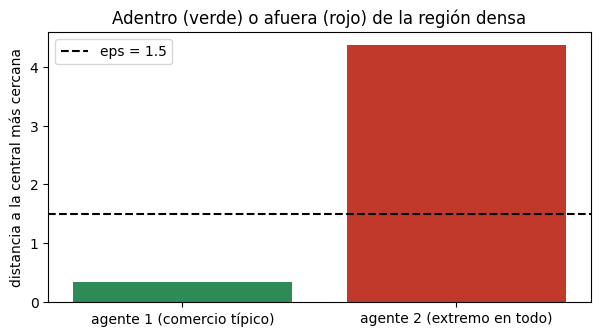

In [8]:
buscador = NearestNeighbors(n_neighbors=1).fit(centrales)
nuevos = pd.DataFrame([{"log_tamano": np.log10(800), "estacionalidad": np.log2(1.4), "volatilidad": 0.12, "tendencia_anual": np.log10(1.03), "frac_caidas": 1 / 6, "cv": 0.25},
                       {"log_tamano": np.log10(300), "estacionalidad": np.log2(3.5), "volatilidad": 0.45, "tendencia_anual": np.log10(0.70), "frac_caidas": 0.40, "cv": 1.2}])[COLUMNAS]
z_nuevos = preparar.transform(nuevos)
distancias = buscador.kneighbors(z_nuevos)[0][:, 0]
for i in range(2):
    g = int(kmedias.predict(z_nuevos[[i]])[0])
    print(f"Agente {i + 1}: distancia a la central más cercana {distancias[i]:.2f} → {'se parece a agentes que tenemos' if distancias[i] <= EPS else 'RUIDO: no se parece a ninguno'} · k-medias: {nombres[g]}")
fig, ax = plt.subplots(figsize=(7, 3.5))
ax.bar(["agente 1 (comercio típico)", "agente 2 (extremo en todo)"], distancias, color=["#2e8b57" if d <= EPS else "#c0392b" for d in distancias]); ax.axhline(EPS, color="black", ls="--", label=f"eps = {EPS}")
ax.set_ylabel("distancia a la central más cercana"); ax.legend(); ax.set_title("Adentro (verde) o afuera (rojo) de la región densa")
plt.show()

### Guardar

La preparación (el escalador), las centrales de DBSCAN, eps, qué series actuales son ruido, k-medias, los nombres y los perfiles: todo en un archivo que la app carga.

In [9]:
import joblib
joblib.dump({"preparar": preparar, "centrales": centrales, "eps": EPS, "ruido": ruido, "kmedias": kmedias, "nombres": nombres, "columnas": COLUMNAS, "perfiles": perfiles[COLUMNAS]}, "densidad_cammesa_43.joblib")
print(f"Guardado: densidad_cammesa_43.joblib ({len(centrales)} centrales, eps {EPS})")

Guardado: densidad_cammesa_43.joblib (779 centrales, eps 1.5)


### La aplicación Streamlit, desde el cuaderno

La celda siguiente escribe `app_cammesa_43.py` (seis controles con el perfil del agente en unidades que se entienden; dice si se parece a alguno, a qué distancia, y a qué grupo de k-medias iría). La de después la abre.

In [10]:
%%writefile app_cammesa_43.py
# Clase 43 sobre CAMMESA · Agrupamiento por densidad · aplicación Streamlit
# Carga lo guardado por el cuaderno (escalador, centrales de DBSCAN, eps, k-medias) y dice si un agente nuevo se parece a alguno.
# Para abrirla:  streamlit run app_cammesa_43.py
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import streamlit as st
from sklearn.neighbors import NearestNeighbors

st.set_page_config(page_title="¿Se parece a algún agente?", layout="centered")
st.title("¿Este agente se parece a alguno que ya tenemos?")
st.caption("DBSCAN sobre el perfil de 868 series de demanda-ltimos-aos.csv (CAMMESA, clase 43): una región densa y ruido. Y a qué grupo de k-medias iría (clase 41).")

g = joblib.load("densidad_cammesa_43.joblib")
preparar, centrales, EPS, kmedias, nombres, COLUMNAS, perfiles = g["preparar"], g["centrales"], g["eps"], g["kmedias"], g["nombres"], g["columnas"], g["perfiles"]
es_ruido = g["ruido"]
buscador = NearestNeighbors(n_neighbors=1).fit(centrales)

st.subheader("Perfil del agente")
c1, c2 = st.columns(2)
mwh = c1.number_input("Demanda media (MWh por mes)", 1.0, 800_000.0, 800.0, step=50.0)
ver_inv = c1.slider("Verano / invierno (1 = parejo)", 0.3, 4.0, 1.4, step=0.05)
volatilidad = c1.slider("Variación mensual típica (%)", 0.0, 80.0, 12.0, step=0.5)
crecimiento = c2.slider("Crecimiento por año (%)", -60.0, 60.0, 3.0, step=0.5)
caidas = c2.slider("Meses con caída de más de 15 % (%)", 0.0, 60.0, 17.0, step=1.0)
cv = c2.slider("Variabilidad (desvío / media)", 0.0, 2.0, 0.25, step=0.01)

fila = pd.DataFrame([{"log_tamano": np.log10(mwh), "estacionalidad": np.log2(ver_inv), "volatilidad": volatilidad / 100,
                      "tendencia_anual": np.log10(1 + crecimiento / 100), "frac_caidas": caidas / 100, "cv": cv}])[COLUMNAS]
z = preparar.transform(fila)
distancia = float(buscador.kneighbors(z)[0][0, 0])
adentro = distancia <= EPS
grupo = int(kmedias.predict(z)[0])

st.subheader("Resultado")
m1, m2 = st.columns(2)
m1.metric("Distancia a la central más cercana", f"{distancia:.2f}", help=f"eps = {EPS}: más lejos que eso, ruido")
m2.metric("Según la densidad", "se parece a agentes que tenemos" if adentro else "RUIDO: no se parece a ninguno")
st.write(f"k-medias (clase 41) lo mandaría al grupo «{nombres[grupo]}»" + ("." if adentro else ", pero a esa distancia no hay agentes parecidos: el grupo le queda grande."))

fig, (a, b) = plt.subplots(1, 2, figsize=(11, 4))
a.bar(["este agente"], [distancia], color="#2e8b57" if adentro else "#c0392b"); a.axhline(EPS, color="black", ls="--", label=f"eps = {EPS}")
a.set_ylabel("distancia a la central más cercana (escalada)"); a.set_ylim(0, max(EPS * 2, distancia * 1.2)); a.legend(); a.set_title("Adentro o afuera de la región densa")
b.scatter(perfiles.loc[~es_ruido, "log_tamano"], perfiles.loc[~es_ruido, "volatilidad"], s=8, alpha=0.4, color="#0055a5", label="en la región densa")
b.scatter(perfiles.loc[es_ruido, "log_tamano"], perfiles.loc[es_ruido, "volatilidad"], s=14, alpha=0.8, color="#9ca3af", marker="x", label="ruido (DBSCAN)")
b.scatter([np.log10(mwh)], [volatilidad / 100], marker="*", s=350, color="#2e8b57" if adentro else "#c0392b", edgecolor="black", zorder=5, label="este agente")
b.set_xlabel("log₁₀ del tamaño (MWh por mes)"); b.set_ylabel("volatilidad"); b.set_ylim(0, max(0.8, volatilidad / 100 * 1.1)); b.legend(fontsize=7); b.set_title("Dónde cae entre las 868 series")
plt.tight_layout(); st.pyplot(fig)

Writing app_cammesa_43.py


La celda que sigue abre la app. Mientras corre, la celda queda ocupada; para volver se interrumpe el kernel (■).

In [11]:
!streamlit run app_cammesa_43.py

^C


## Qué quedó

- DBSCAN: un grupo es una cadena de puntos **centrales** (con `min_samples` vecinos a menos de `eps`); cualquier forma, sin k, y lo que no llega a ninguna central es **ruido** (−1). `eps` es una distancia: hay que escalar, y no se deja por defecto (la curva del 5.º vecino ayuda).
- Sobre los agentes, la densidad encuentra **una sola región** y ruido: no hay islas; los grupos de la clase 41 son cortes de un continuo. El ruido son los agentes extremos (muy volátiles, muy variables, con muchas caídas): la lista de la clase 46.
- **El grupo chico de k-medias era, en su mayor parte, ruido**: k-medias tiene que ubicar a todos y les armó un grupo propio a los extremos; la densidad dice que no forman grupo.
- Sin `predict`: la distancia a la central más cercana contra eps dice si un agente nuevo se parece a alguno. k-medias siempre contesta «a qué se parece más»; la densidad contesta «si se parece a algo».
- Evaluar sin etiquetas: silueta (mayor), Davies-Bouldin (menor), Calinski-Harabasz (mayor); miden compacidad y separación, no verdad, y no coinciden entre sí.